# Experiment 1: Time and frequency domain, and the pendulum
Builds a three-tone signal, reads its spectrum, demonstrates aliasing, and integrates a damped pendulum.
Every figure is written to `figs/`, every number used in the report to `results.json`.

In [1]:
import json, platform
import numpy as np, scipy, matplotlib
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.special import ellipk

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "font.size": 10})
R = {"versions": dict(python=platform.python_version(), numpy=np.__version__,
                      scipy=scipy.__version__, matplotlib=matplotlib.__version__)}
print(R["versions"])

{'python': '3.13.5', 'numpy': '2.3.2', 'scipy': '1.16.1', 'matplotlib': '3.10.8'}


## 1. Sampling parameters and the constructed signal

{'fs': 500.0, 'T': 2.0, 'N': 1000, 'df': 0.5, 'nyquist': 250.0}


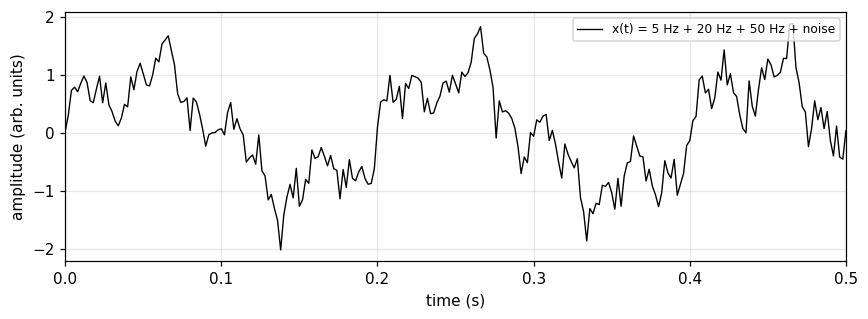

In [2]:
fs, T = 500.0, 2.0                       # sampling rate (Hz), record length (s)
t = np.arange(0, T, 1/fs)
N = t.size
df = fs / N
COMPONENTS = [(5, 1.00), (20, 0.50), (50, 0.25)]   # (frequency Hz, amplitude)

def make_signal(t, seed=0):
    rng = np.random.default_rng(seed)    # seeded: reproducible noise
    x = sum(a*np.sin(2*np.pi*f*t) for f, a in COMPONENTS)
    return x + 0.20*rng.standard_normal(t.size)

def amplitude_spectrum(x, fs):
    X = np.fft.rfft(x)                   # real input -> one-sided spectrum
    f = np.fft.rfftfreq(x.size, d=1/fs)  # matching frequency axis (Hz)
    amp = np.abs(X) * 2.0 / x.size       # peak height = sine amplitude
    amp[0] /= 2.0                        # DC term is not doubled
    return f, amp

x = make_signal(t)
R["sampling"] = dict(fs=fs, T=T, N=N, df=df, nyquist=fs/2)
print(R["sampling"])

fig, ax = plt.subplots(figsize=(8, 3))
m = t <= 0.5
ax.plot(t[m], x[m], lw=0.9, color="k", label="x(t) = 5 Hz + 20 Hz + 50 Hz + noise")
ax.set(xlabel="time (s)", ylabel="amplitude (arb. units)", xlim=(0, 0.5))
ax.legend(loc="upper right", fontsize=8); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig("figs/fig1_1_signal_time.png"); plt.show()

## 2. One-sided amplitude spectrum, and leakage with T = 1.7 s

[{'set_f': 5, 'meas_f': 5.0, 'set_a': 1.0, 'meas_a': 1.007761407576205}, {'set_f': 20, 'meas_f': 20.0, 'set_a': 0.5, 'meas_a': 0.4917110202063449}, {'set_f': 50, 'meas_f': 50.0, 'set_a': 0.25, 'meas_a': 0.25208452812036897}]
{'N': 850, 'df': 0.5882352941176471, 'peaks': [{'set_f': 5, 'peak_f': 4.705882352941177, 'peak_a': 0.6643151202949674, 'bins_above_10pct': 6}, {'set_f': 20, 'peak_f': 20.0, 'peak_a': 0.4859405439359952, 'bins_above_10pct': 1}, {'set_f': 50, 'peak_f': 50.0, 'peak_a': 0.25869982226263377, 'bins_above_10pct': 1}]}


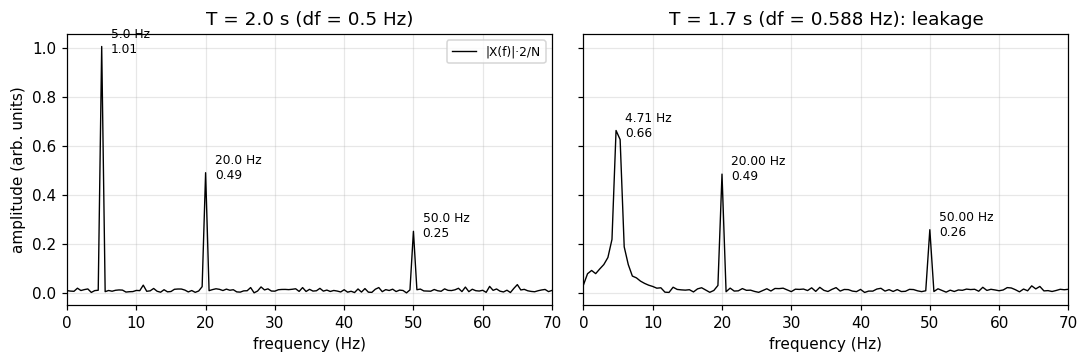

In [3]:
f, amp = amplitude_spectrum(x, fs)
measured = []
for f0, a0 in COMPONENTS:
    win = (f > f0 - 2) & (f < f0 + 2)
    k = np.argmax(amp * win)
    measured.append(dict(set_f=f0, meas_f=float(f[k]), set_a=a0, meas_a=float(amp[k])))
R["spectrum"] = measured

# same signal, record length 1.7 s: tones fall between bins -> leakage
t17 = np.arange(0, 1.7, 1/fs)
f17, amp17 = amplitude_spectrum(make_signal(t17), fs)
leak = []
for f0, a0 in COMPONENTS:
    win = (f17 > f0 - 2) & (f17 < f0 + 2)
    k = np.argmax(amp17 * win)
    leak.append(dict(set_f=f0, peak_f=float(f17[k]), peak_a=float(amp17[k]),
                     bins_above_10pct=int(((amp17 > 0.1*a0) & win).sum())))
R["leakage_T1.7"] = dict(N=t17.size, df=fs/t17.size, peaks=leak)
print(measured); print(R["leakage_T1.7"])

fig, axs = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, ff, aa, title in ((axs[0], f, amp, "T = 2.0 s (df = 0.5 Hz)"),
                          (axs[1], f17, amp17, "T = 1.7 s (df = 0.588 Hz): leakage")):
    ax.plot(ff, aa, lw=0.9, color="k", label="|X(f)|·2/N")
    ax.set(xlim=(0, 70), xlabel="frequency (Hz)", title=title)
    ax.grid(alpha=0.3)
for d in measured:
    axs[0].annotate(f"{d['meas_f']:.1f} Hz\n{d['meas_a']:.2f}", (d["meas_f"], d["meas_a"]),
                    xytext=(6, -4), textcoords="offset points", fontsize=8)
for d in leak:
    axs[1].annotate(f"{d['peak_f']:.2f} Hz\n{d['peak_a']:.2f}", (d["peak_f"], d["peak_a"]),
                    xytext=(6, -4), textcoords="offset points", fontsize=8)
axs[0].set_ylabel("amplitude (arb. units)"); axs[0].legend(fontsize=8)
fig.tight_layout(); fig.savefig("figs/fig1_2_spectrum.png"); plt.show()

## 3. Aliasing: a 5 Hz sine sampled at 8 Hz

{'fs': 8.0, 'f_true': 5.0, 'nyquist': 4.0, 'measured_peak': 3.0, 'predicted': 3.0}


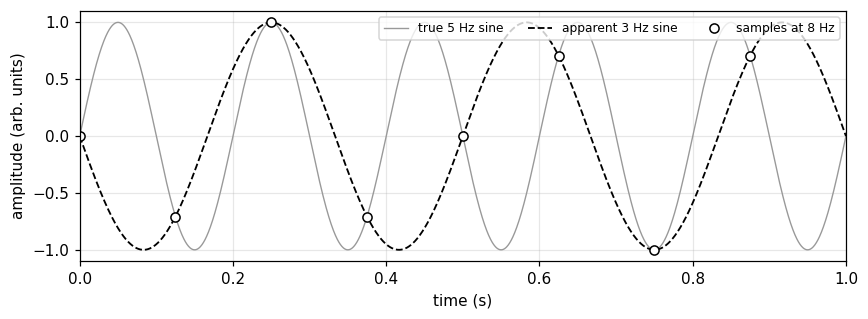

In [4]:
fs_a, f_true = 8.0, 5.0
t_a = np.arange(0, 1.0, 1/fs_a)
x_a = np.sin(2*np.pi*f_true*t_a)
fa, Aa = amplitude_spectrum(x_a, fs_a)
f_alias = float(fa[np.argmax(Aa)])
R["aliasing"] = dict(fs=fs_a, f_true=f_true, nyquist=fs_a/2, measured_peak=f_alias,
                     predicted=abs(fs_a - f_true))
print(R["aliasing"])

tc = np.linspace(0, 1, 2000)
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(tc, np.sin(2*np.pi*f_true*tc), lw=0.9, color="0.6", label="true 5 Hz sine")
ax.plot(tc, -np.sin(2*np.pi*f_alias*tc), "--", lw=1.2, color="k", label=f"apparent {f_alias:.0f} Hz sine")
ax.plot(t_a, x_a, "o", ms=6, mfc="w", mec="k", label="samples at 8 Hz")
ax.set(xlabel="time (s)", ylabel="amplitude (arb. units)", xlim=(0, 1))
ax.legend(loc="upper right", fontsize=8, ncol=3); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig("figs/fig1_3_aliasing.png"); plt.show()

## 4. The pendulum: damping and phase portrait

T0 = 2.0061 s


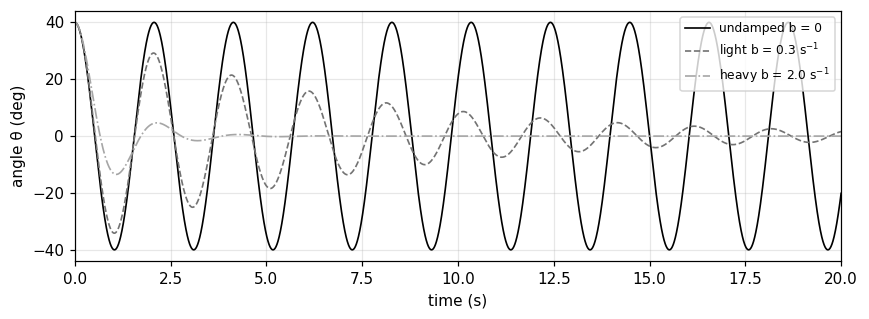

In [5]:
g, L = 9.81, 1.0
T0 = 2*np.pi*np.sqrt(L/g)
DAMPING = (0.0, 0.3, 2.0)                # b/m in 1/s

def pendulum(t, y, b):                   # solve_ivp calls f(t, y)
    theta, omega = y
    return [omega, -b*omega - (g/L)*np.sin(theta)]

def simulate(theta0_deg, b, T=20.0, n=4000):
    te = np.linspace(0, T, n)
    sol = solve_ivp(pendulum, [0, T], [np.deg2rad(theta0_deg), 0.0], args=(b,),
                    t_eval=te, rtol=1e-9, atol=1e-12)
    return sol.t, sol.y[0], sol.y[1]

R["T0"] = T0; R["damping"] = DAMPING
print("T0 =", round(T0, 4), "s")

runs = {b: simulate(40, b) for b in DAMPING}
labels = {0.0: "undamped b = 0", 0.3: "light b = 0.3 s$^{-1}$", 2.0: "heavy b = 2.0 s$^{-1}$"}
styles = {0.0: ("k", "-"), 0.3: ("0.45", "--"), 2.0: ("0.65", "-.")}
fig, ax = plt.subplots(figsize=(8, 3))
for b, (tt, th, _) in runs.items():
    ax.plot(tt, np.rad2deg(th), color=styles[b][0], ls=styles[b][1], lw=1.1, label=labels[b])
ax.set(xlabel="time (s)", ylabel="angle θ (deg)", xlim=(0, 20))
ax.legend(fontsize=8, loc="upper right"); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig("figs/fig1_4_pendulum_damping.png"); plt.show()

## 5. Period against amplitude: zero crossings and spectrum

{'angle': 5, 'zc': 2.00702191356248, 'spec': 2.000166680556713, 'exact': 2.007021914469057, 'ratio': np.float64(1.0004761720340691)}
{'angle': 45, 'zc': 2.08625587045496, 'spec': 2.0691379454034964, 'exact': 2.0862558726143674, 'ratio': np.float64(1.0399733421203654)}
{'angle': 95, 'zc': 2.417384380517157, 'spec': 2.4002000166680557, 'exact': 2.417384395811996, 'ratio': np.float64(1.2050369031904764)}
{'angle': 135, 'zc': 3.0651647129328463, 'spec': 3.0002500208350695, 'exact': 3.065164746629204, 'ratio': np.float64(1.527947571437164)}
{'angle': 175, 'zc': 5.772783564438493, 'spec': 6.000500041670139, 'exact': 5.7727848904177765, 'ratio': np.float64(2.8776628513631906)}


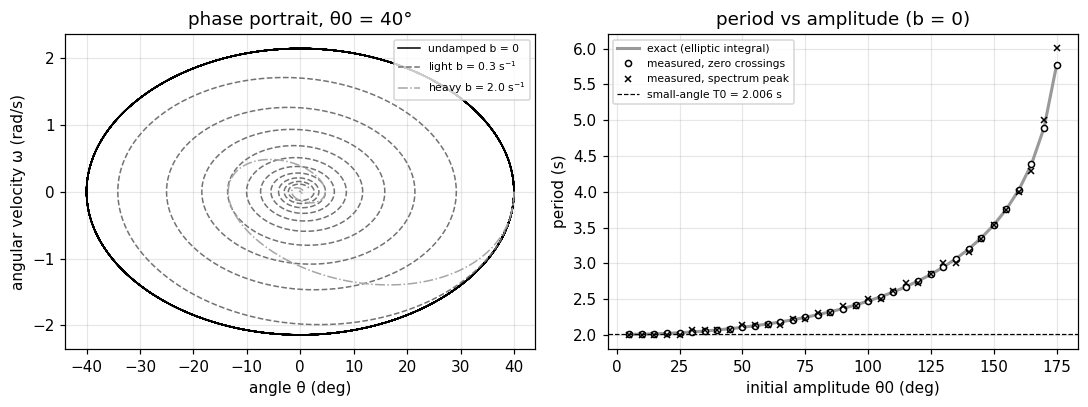

In [6]:
def period_zero_crossings(t, th):
    s = np.sign(th)
    idx = np.where((s[:-1] < 0) & (s[1:] >= 0))[0]          # upward crossings
    tc = t[idx] - th[idx]*(t[idx+1]-t[idx])/(th[idx+1]-th[idx])  # linear interpolation
    return float(np.mean(np.diff(tc)))

def period_spectrum(t, th):
    fsp = 1/(t[1]-t[0])
    A = np.abs(np.fft.rfft(th)); fr = np.fft.rfftfreq(th.size, 1/fsp)
    return float(1/fr[1:][np.argmax(A[1:])])                # skip DC bin

def period_exact(theta0_deg):                               # 4 sqrt(L/g) K(k), k = sin(θ0/2)
    k = np.sin(np.deg2rad(theta0_deg)/2)
    return float(4*np.sqrt(L/g)*ellipk(k**2))

sweep = np.arange(5, 180, 5)
rows = []
for a in sweep:
    tt, th, _ = simulate(a, 0.0, T=60.0, n=12000)
    rows.append(dict(angle=int(a), zc=period_zero_crossings(tt, th), spec=period_spectrum(tt, th),
                     exact=period_exact(a)))
for r in rows: r["ratio"] = r["zc"]/T0
R["period_table"] = [r for r in rows if r["angle"] in (5, 45, 95, 135, 175)]
for r in R["period_table"]: print(r)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.8))
for b, (tt, th, om) in runs.items():
    a1.plot(np.rad2deg(th), om, color=styles[b][0], ls=styles[b][1], lw=1.0, label=labels[b])
a1.set(xlabel="angle θ (deg)", ylabel="angular velocity ω (rad/s)", title="phase portrait, θ0 = 40°")
a1.legend(fontsize=7); a1.grid(alpha=0.3)
A = [r["angle"] for r in rows]
a2.plot(A, [r["exact"] for r in rows], "-", color="0.6", lw=2, label="exact (elliptic integral)")
a2.plot(A, [r["zc"] for r in rows], "o", ms=4, mfc="w", mec="k", label="measured, zero crossings")
a2.plot(A, [r["spec"] for r in rows], "x", ms=4, color="k", label="measured, spectrum peak")
a2.axhline(T0, ls="--", color="k", lw=0.8, label=f"small-angle T0 = {T0:.3f} s")
a2.set(xlabel="initial amplitude θ0 (deg)", ylabel="period (s)", title="period vs amplitude (b = 0)")
a2.legend(fontsize=7); a2.grid(alpha=0.3)
fig.tight_layout(); fig.savefig("figs/fig1_5_phase_period.png"); plt.show()

In [7]:
json.dump(R, open("results.json", "w"), indent=1)
print("saved results.json")

saved results.json
